In [2]:
import numpy as np
from amuse.ic.kroupa import new_kroupa_mass_distribution
from amuse.units import units
from amuse.ic.salpeter import new_salpeter_mass_distribution
import matplotlib.pyplot as plt
from amuse.lab import nbody_system
from amuse.lab import *
from amuse.ext.orbital_elements import new_binary_from_orbital_elements
from matplotlib import pyplot as plt
from amuse.plot import scatter
from amuse.ext.orbital_elements import get_orbital_elements_from_binary
from amuse.community.ph4.interface import Ph4
from amuse.ext.orbital_elements import semimajor_axis_to_orbital_period

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
10888543869361741031    7.000e+01   Black Hole    0.000e+00   -1.770e-07   -0.000e+00   -4.225e-01   -0.000e+00   -0.000e+00
 4368390215679221087    1.000e+00         Star    0.000e+00    1.239e-05    0.000e+00    2.958e+01    0.000e+00    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
star orbit: (quantity<70.0 1.98892e+30 * kg>, quantity<1.0 1.98892e+30 * kg>, quantity<30.0 149597870691.0 * m>, 0.0, quantity<0.0 rad>, quantity<0.0 rad>, quantity<0.

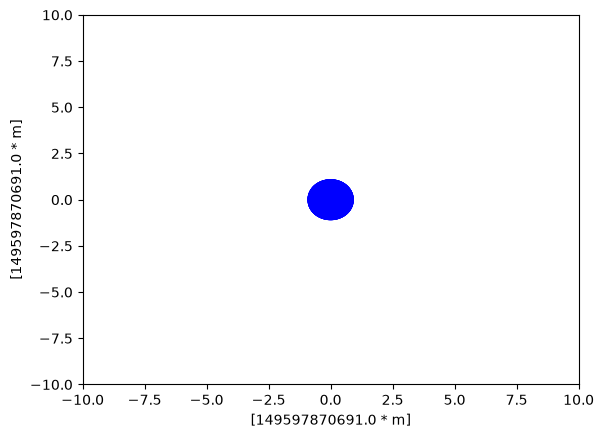

In [17]:
def initial_conditions():
    # Define initial conditions for the black hole binary
    mass_blackhole_1 = 70 | units.MSun
    mass_star = 1 | units.MSun
    semi_major_axis_star = 30 | units.AU
    eccentricity_star = 0.0

    bodies = new_binary_from_orbital_elements(
        mass1 = mass_blackhole_1, 
        mass2 = mass_star, 
        semimajor_axis = semi_major_axis_star, 
        eccentricity = eccentricity_star, 
        G=constants.G) 
    bodies.name = ['Black Hole', 'Star']
    return bodies

def compute_energy(particles):
    return particles.kinetic_energy() + particles.potential_energy()

if __name__ == "__main__":
    bodies = initial_conditions()
    print(bodies)

    sma_star = []
    e_star = []

    star_orbit = get_orbital_elements_from_binary(bodies[0:2], constants.G)
    print(f'star orbit: {star_orbit}')

    sma_star.append(star_orbit[2])
    e_star.append(star_orbit[3])

    converter = nbody_system.nbody_to_si(bodies.mass.sum(), 30 | units.AU)
    gravity = Ph4(converter)
    gravity.particles.add_particles(bodies) #makes a copy of bodies in the nbody code called gravity
    channel_from_gravity_to_bodies = gravity.particles.new_channel_to(bodies) #makes a solid link from the memory in the python script to the memory in the nbody code

    Ek0 = bodies.kinetic_energy()
    Ep0 = bodies.potential_energy()
    Etot = Ek0 + Ep0

    Porb = semimajor_axis_to_orbital_period(sma_star[0], bodies[0:2].mass.sum())
    time = 0 | units.yr
    dt = Porb / 100
    #index = 0
    while gravity.model_time < Porb:
        time += dt
        gravity.evolve_model(time)
        channel_from_gravity_to_bodies.copy()
        Ek = bodies.kinetic_energy()
        Ep = bodies.potential_energy()
        #print(f'time = {time.in_(units.yr)}, dEtot = {(Ek+Ep-Etot)/Etot}')
        plt.xlim(-10, 10)
        plt.ylim(-10, 10)
        scatter(bodies.x, bodies.y, s = 2+300*np.sqrt(bodies.mass/bodies.mass.sum()), c = 'blue')
        #index += 1
        #filename = f'snapshot_i{index:04}.jpg' #makes images for the movie. has a lot of image outputs
        #plt.savefig(filename)
        #plt.close()